In [1]:
# Cell 1: Imports used for data generation, plotting, and majority voting
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

In [2]:
# Cell 2: Create a reproducible 1D dataset and split into train/test
np.random.seed(42)

data = np.random.rand(100)
train_data = data[:50]
test_data = data[50:]

# Label rule: values <= 0.5 are Class1, otherwise Class2
train_labels = ["Class1" if x <= 0.5 else "Class2" for x in train_data]

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))
print("Training class counts:", Counter(train_labels))

Training samples: 50
Testing samples: 50
Training class counts: Counter({'Class1': 28, 'Class2': 22})


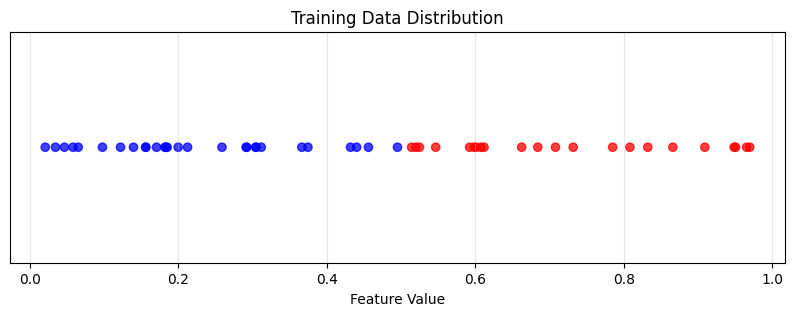

In [3]:
# Cell 3: Visualize the training points on a single feature axis
plt.figure(figsize=(10, 3))
point_colors = ["blue" if label == "Class1" else "red" for label in train_labels]

plt.scatter(train_data, np.zeros_like(train_data), c=point_colors, alpha=0.75)
plt.title("Training Data Distribution")
plt.xlabel("Feature Value")
plt.yticks([])
plt.grid(alpha=0.3)
plt.show()

In [4]:
# Cell 4: Define distance metric and k-NN prediction function
def euclidean_distance(x1, x2):
    return abs(x1 - x2)


def knn_classifier(train_values, train_targets, test_point, k):
    # Compute distance from test point to every training point
    distances = []
    for idx in range(len(train_values)):
        dist = euclidean_distance(test_point, train_values[idx])
        distances.append((dist, train_targets[idx]))

    # Pick k nearest labels and return the majority class
    distances.sort(key=lambda pair: pair[0])
    k_nearest_labels = [label for _, label in distances[:k]]
    return Counter(k_nearest_labels).most_common(1)[0][0]

In [5]:
# Cell 5: Predict test labels for multiple k values
k_values = [1, 3, 5, 20]
all_predictions = {}

for k in k_values:
    preds = [knn_classifier(train_data, train_labels, point, k) for point in test_data]
    all_predictions[k] = preds
    print(f"k = {k} ->", dict(Counter(preds)))

k = 1 -> {'Class2': 25, 'Class1': 25}
k = 3 -> {'Class2': 26, 'Class1': 24}
k = 5 -> {'Class2': 26, 'Class1': 24}
k = 20 -> {'Class2': 26, 'Class1': 24}


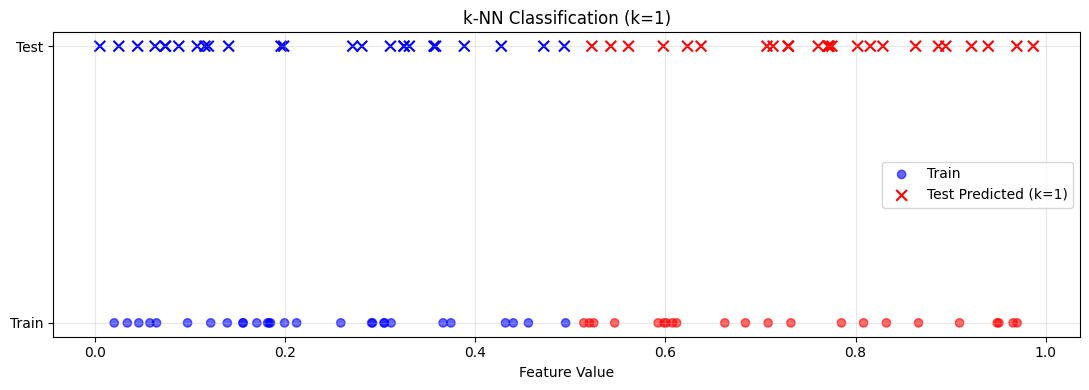

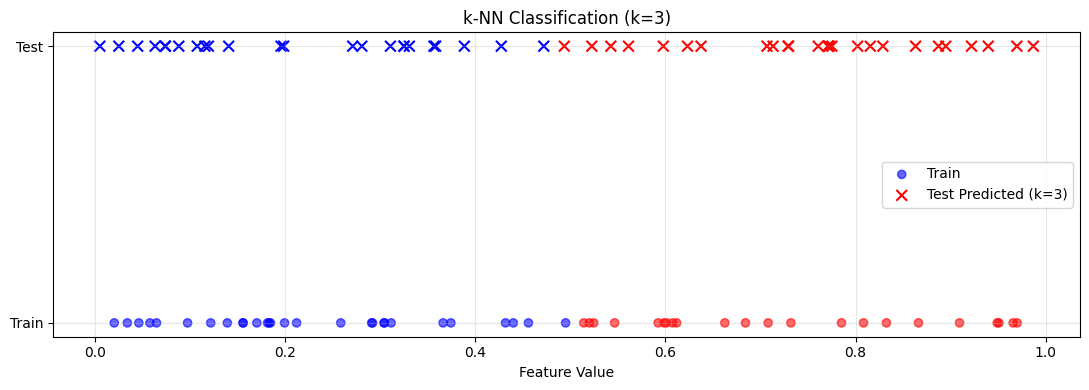

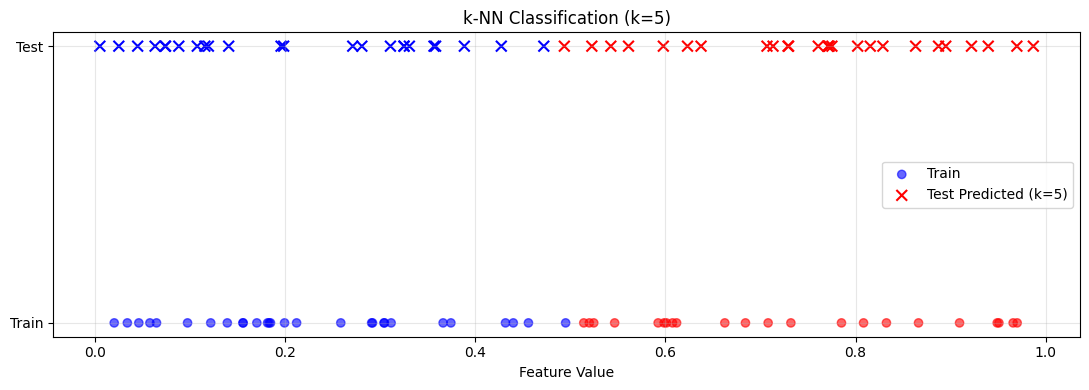

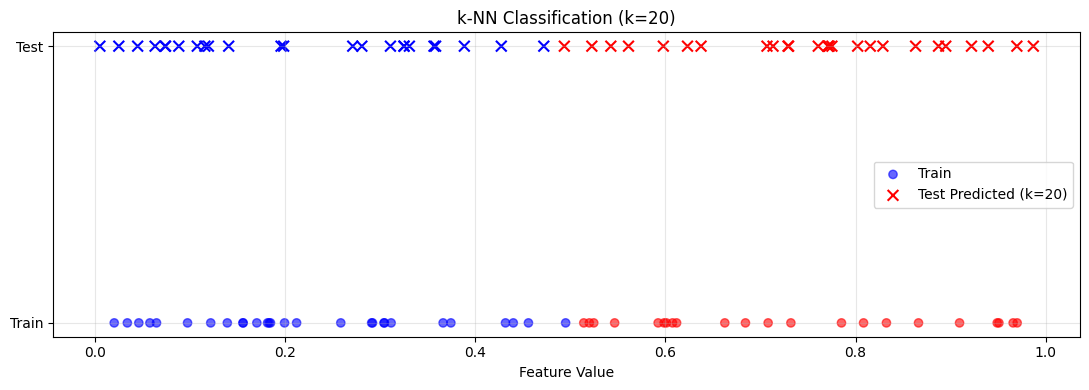

In [6]:
# Cell 6: Compare train points with predicted test classes for each k
for k in k_values:
    predicted_labels = all_predictions[k]

    plt.figure(figsize=(11, 4))
    train_colors = ["blue" if l == "Class1" else "red" for l in train_labels]
    test_colors = ["blue" if l == "Class1" else "red" for l in predicted_labels]

    plt.scatter(train_data, [0] * len(train_data), c=train_colors, alpha=0.6, label="Train")
    plt.scatter(test_data, [1] * len(test_data), c=test_colors, marker="x", s=60, label=f"Test Predicted (k={k})")

    plt.title(f"k-NN Classification (k={k})")
    plt.xlabel("Feature Value")
    plt.yticks([0, 1], ["Train", "Test"])
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()